# Taller Segunda Edición: Estimación CAPM para Solana (SOL) y Kopin Corporation (KOPN)
**Materia:** Valoración de Activos (DEFI 2)  
**Estudiante:** Julián Duarte  
**Profesor:** Valoración de Activos - DEFI  
**Fecha:** Septiembre de 2026  

---

## Resumen del Entregable
Este cuaderno Jupyter constituye la evidencia técnica y econométrica completa del **Taller de Valoración de Activos (Segunda Edición)**. Se evalúan dos activos de perfil diferenciado:
1. **Solana (SOL):** Criptoactivo Layer-1 de alta capitalización frente al **Nasdaq Crypto Index (NCI)** ($K = 365$ días continuos).
2. **Kopin Corporation (KOPN):** Acción de bajo precio (*penny stock* micro-cap de tecnología militar y médica, $< 	ext{USD } 1.00$) frente al **Technology Select Sector SPDR Fund (XLK)** ($K = 252$ días bursátiles).

### Estructura de Análisis en este Notebook:
- **Paso 1:** Configuración del entorno y carga de datos sin fricción.
- **Paso 2:** Estimación por Mínimos Cuadrados Ordinarios (**OLS** / MCO) y análisis de sus supuestos.
- **Paso 3:** Corrección por Heterocedasticidad mediante matriz **HC1 (White con corrección de grados de libertad)**.
- **Paso 4:** Corrección simultánea por Heterocedasticidad y Autocorrelación Residual mediante matriz **Newey-West (HAC)** ($L=5$ rezagos de Bartlett).
- **Paso 5:** Comparativa econométrica directa en tabla y bosquejo de intervalos de confianza al 95%.
- **Paso 6:** Desglose del **Retorno Requerido del CAPM ($E(R_i)$)**, tasa libre de riesgo ($R_f$), prima de riesgo de mercado y Alpha de Jensen ($lpha$).
- **Paso 7:** Métricas complejas de riesgo financiero (Drawdown Máximo, Iliquidez de Amihud, Beta Bajista, Beta Dimson).
- **Paso 8:** Conclusiones y dictamen final de inversión para la gestión de portafolios.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de visualizaciones
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# Ubicación de directorios
BASE_DIR = Path.cwd().parent if (Path.cwd().parent / '01_datos').exists() else Path.cwd()
DATOS_DIR = BASE_DIR / '01_datos'
GRAFICOS_DIR = BASE_DIR / '04_graficos'

print("Directorio de trabajo identificado:", BASE_DIR)
print("Archivos de datos disponibles:", [f.name for f in DATOS_DIR.glob('*.csv')])

Directorio de trabajo identificado: /home/julianxd/code/DEFI 2/TALLER 1/07_taller_segunda_edicion
Archivos de datos disponibles: ['evidencia_seleccion_activos.csv', 'datos_taller_2_edicion.csv', 'tabla_maestra_segunda_edicion.csv', 'comparativa_modelos_hac_hc1_ols.csv']


In [2]:
# Carga de la base de datos principal y tablas maestras
df_base = pd.read_csv(DATOS_DIR / 'datos_taller_2_edicion.csv', parse_dates=['Date'])
master = pd.read_csv(DATOS_DIR / 'tabla_maestra_segunda_edicion.csv')
comp_models = pd.read_csv(DATOS_DIR / 'comparativa_modelos_hac_hc1_ols.csv')

print(f"Dataset cargado con {len(df_base)} observaciones diarias.")
print(f"Rango temporal: desde {df_base['Date'].min().strftime('%Y-%m-%d')} hasta {df_base['Date'].max().strftime('%Y-%m-%d')}")

# Vista preliminar de precios y excesos de retorno
df_base[['Date', 'SOL_Price', 'NCI_Price', 'KOPN_Price', 'XLK_Price', 'SOL_Excess_Return', 'KOPN_Excess_Return']].head()

Dataset cargado con 499 observaciones diarias.
Rango temporal: desde 2024-08-27 hasta 2026-08-24


,Date,SOL_Price,NCI_Price,KOPN_Price,XLK_Price,SOL_Excess_Return,KOPN_Excess_Return
0,2024-08-27,146.897095,3037.17,0.97,109.909653,-0.065899,-0.067510
1,2024-08-28,143.891388,3056.53,0.94,108.393074,-0.020600,-0.031129
2,2024-08-29,140.054031,3058.95,1.01,107.414970,-0.026808,0.074266
3,2024-08-30,138.099991,3050.90,0.97,108.842613,-0.014091,-0.039805
4,2024-09-03,127.577583,2963.26,0.86,103.843353,-0.076333,-0.113603


---
## Paso 2. Estimación Econométrica MCO / OLS (Mínimos Cuadrados Ordinarios)

El modelo CAPM especifica la relación lineal entre el exceso de retorno del activo $i$ ($R_{i,t} - R_{f,t}$) y el exceso de retorno del mercado $m$ ($R_{m,t} - R_{f,t}$):

$$R_{i,t} - R_{f,t} = lpha_i + eta_i (R_{m,t} - R_{f,t}) + arepsilon_{i,t}$$

En la estimación OLS estándar se asume que:
1. **Homocedasticidad:** $	ext{Var}(arepsilon_{i,t} \mid X) = \sigma^2$ (varianza de los residuos constante en el tiempo).
2. **Ausencia de Autocorrelación:** $	ext{Cov}(arepsilon_{i,t}, arepsilon_{i,t-j}) = 0$ para todo $j 
eq 0$ (los residuos no están correlacionados entre días).

A continuación estimamos el modelo OLS clásico para **SOL** (frente al NCI) y **KOPN** (frente al XLK).

In [3]:
def estimate_ols(df, ticker, benchmark):
    ri_e = df[f'{ticker}_Excess_Return']
    rm_e = df[f'{benchmark}_Excess_Return']
    X = sm.add_constant(rm_e)
    model_ols = sm.OLS(ri_e, X, missing='drop').fit()
    return model_ols

ols_sol = estimate_ols(df_base, 'SOL', 'NCI')
ols_kopn = estimate_ols(df_base, 'KOPN', 'XLK')

print("=== OLS SOL (Solana vs NCI) ===")
print(f"Alpha Diario: {ols_sol.params.iloc[0]:.6f} | Alpha Anual (365d): {ols_sol.params.iloc[0]*365*100:.2f}%")
print(f"Beta OLS: {ols_sol.params.iloc[1]:.4f} | Error Estándar OLS: {ols_sol.bse.iloc[1]:.4f}")
print(f"Intervalo de Confianza 95% OLS: [{ols_sol.conf_int().iloc[1,0]:.4f}, {ols_sol.conf_int().iloc[1,1]:.4f}]")
print(f"R²: {ols_sol.rsquared:.4f}")

print("")
print("=== OLS KOPN (Kopin Corp vs XLK) ===")
print(f"Alpha Diario: {ols_kopn.params.iloc[0]:.6f} | Alpha Anual (252d): {ols_kopn.params.iloc[0]*252*100:.2f}%")
print(f"Beta OLS: {ols_kopn.params.iloc[1]:.4f} | Error Estándar OLS: {ols_kopn.bse.iloc[1]:.4f}")
print(f"Intervalo de Confianza 95% OLS: [{ols_kopn.conf_int().iloc[1,0]:.4f}, {ols_kopn.conf_int().iloc[1,1]:.4f}]")
print(f"R²: {ols_kopn.rsquared:.4f}")

=== OLS SOL (Solana vs NCI) ===
Alpha Diario: -0.000791 | Alpha Anual (365d): -28.86%
Beta OLS: 1.2529 | Error Estándar OLS: 0.0400
Intervalo de Confianza 95% OLS: [1.1744, 1.3314]
R²: 0.6641

=== OLS KOPN (Kopin Corp vs XLK) ===
Alpha Diario: 0.003201 | Alpha Anual (252d): 80.66%
Beta OLS: 1.8228 | Error Estándar OLS: 0.1503
Intervalo de Confianza 95% OLS: [1.5274, 2.1182]
R²: 0.2283


---
## Paso 3. Corrección por Heterocedasticidad mediante Matriz HC1 (White)

En las series de tiempo financieras, la volatilidad no es constante; se presentan ráfagas o agrupamientos de alta volatilidad (*volatility clustering*). Esto destruye el supuesto de homocedasticidad.

Cuando hay heterocedasticidad:
- Las estimaciones puntuales de $\hat{lpha}$ y $\hat{eta}$ se mantienen **insesgadas**.
- Sin embargo, los **Errores Estándar (SE)** calculados por OLS son **incorrectos** (generalmente subestimados), haciendo que las pruebas de hipótesis $t$ y los p-valores vendan una falsa precisión.

Para corregirlo se usa la matriz **HC1 (White con factor de corrección de grados de libertad $n/(n-k)$)**:

$$\widehat{	ext{Var}}_{	ext{HC1}}(\hat{eta}) = rac{n}{n-k} (X^T X)^{-1} \left( \sum_{i=1}^n e_i^2 x_i x_i^T ight) (X^T X)^{-1}$$

In [4]:
def estimate_hc1(df, ticker, benchmark):
    ri_e = df[f'{ticker}_Excess_Return']
    rm_e = df[f'{benchmark}_Excess_Return']
    X = sm.add_constant(rm_e)
    model_hc1 = sm.OLS(ri_e, X, missing='drop').fit(cov_type='HC1')
    return model_hc1

hc1_sol = estimate_hc1(df_base, 'SOL', 'NCI')
hc1_kopn = estimate_hc1(df_base, 'KOPN', 'XLK')

print("=== HC1 SOL (Solana vs NCI) ===")
print(f"Beta HC1: {hc1_sol.params.iloc[1]:.4f} | Error Estándar HC1: {hc1_sol.bse.iloc[1]:.4f}")
print(f"Diferencia SE (HC1 vs OLS): {(hc1_sol.bse.iloc[1] - ols_sol.bse.iloc[1]):+.4f} ({(hc1_sol.bse.iloc[1]/ols_sol.bse.iloc[1] - 1)*100:+.2f}%)")
print(f"IC 95% HC1: [{hc1_sol.conf_int().iloc[1,0]:.4f}, {hc1_sol.conf_int().iloc[1,1]:.4f}]")

print("")
print("=== HC1 KOPN (Kopin Corp vs XLK) ===")
print(f"Beta HC1: {hc1_kopn.params.iloc[1]:.4f} | Error Estándar HC1: {hc1_kopn.bse.iloc[1]:.4f}")
print(f"Diferencia SE (HC1 vs OLS): {(hc1_kopn.bse.iloc[1] - ols_kopn.bse.iloc[1]):+.4f} ({(hc1_kopn.bse.iloc[1]/ols_kopn.bse.iloc[1] - 1)*100:+.2f}%)")
print(f"IC 95% HC1: [{hc1_kopn.conf_int().iloc[1,0]:.4f}, {hc1_kopn.conf_int().iloc[1,1]:.4f}]")

=== HC1 SOL (Solana vs NCI) ===
Beta HC1: 1.2529 | Error Estándar HC1: 0.0483
Diferencia SE (HC1 vs OLS): +0.0083 (+20.83%)
IC 95% HC1: [1.1583, 1.3476]

=== HC1 KOPN (Kopin Corp vs XLK) ===
Beta HC1: 1.8228 | Error Estándar HC1: 0.1260
Diferencia SE (HC1 vs OLS): -0.0243 (-16.16%)
IC 95% HC1: [1.5758, 2.0698]


---
## Paso 4. Corrección por Heterocedasticidad y Autocorrelación Residual: Newey-West (HAC)

En activos con fricciones de microestructura de mercado (como las *penny stocks* de baja liquidez o criptoactivos negociados 24/7), los residuos pueden presentar **autocorrelación serial** además de heterocedasticidad.

El estimador **Newey-West (HAC)** soluciona ambos problemas simultáneamente. Aplica un núcleo ponderado de Bartlett con $L$ rezagos:

$$\widehat{	ext{Var}}_{	ext{HAC}}(\hat{eta}) = (X^T X)^{-1} \hat{\Omega}_{	ext{HAC}} (X^T X)^{-1}$$
$$\hat{\Omega}_{	ext{HAC}} = \hat{\Gamma}_0 + \sum_{j=1}^{L} \left(1 - rac{j}{L+1}ight) (\hat{\Gamma}_j + \hat{\Gamma}_j^T)$$

Para datos de frecuencia diaria se fijan $L = 5$ rezagos (correspondientes a una semana bursátil).

In [5]:
def estimate_hac(df, ticker, benchmark, lags=5):
    ri_e = df[f'{ticker}_Excess_Return']
    rm_e = df[f'{benchmark}_Excess_Return']
    X = sm.add_constant(rm_e)
    model_hac = sm.OLS(ri_e, X, missing='drop').fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return model_hac

hac_sol = estimate_hac(df_base, 'SOL', 'NCI', lags=5)
hac_kopn = estimate_hac(df_base, 'KOPN', 'XLK', lags=5)

print("=== NEWEY-WEST HAC SOL (Solana vs NCI) ===")
print(f"Beta HAC: {hac_sol.params.iloc[1]:.4f} | SE HAC: {hac_sol.bse.iloc[1]:.4f}")
print(f"IC 95% HAC: [{hac_sol.conf_int().iloc[1,0]:.4f}, {hac_sol.conf_int().iloc[1,1]:.4f}]")
print(f"p-valor Beta=0: {hac_sol.pvalues.iloc[1]:.5e}")

print("")
print("=== NEWEY-WEST HAC KOPN (Kopin Corp vs XLK) ===")
print(f"Beta HAC: {hac_kopn.params.iloc[1]:.4f} | SE HAC: {hac_kopn.bse.iloc[1]:.4f}")
print(f"IC 95% HAC: [{hac_kopn.conf_int().iloc[1,0]:.4f}, {hac_kopn.conf_int().iloc[1,1]:.4f}]")
print(f"p-valor Beta=0: {hac_kopn.pvalues.iloc[1]:.5e}")

=== NEWEY-WEST HAC SOL (Solana vs NCI) ===
Beta HAC: 1.2529 | SE HAC: 0.0458
IC 95% HAC: [1.1632, 1.3427]
p-valor Beta=0: 7.37693e-165

=== NEWEY-WEST HAC KOPN (Kopin Corp vs XLK) ===
Beta HAC: 1.8228 | SE HAC: 0.1270
IC 95% HAC: [1.5739, 2.0717]
p-valor Beta=0: 1.01833e-46


---
## Paso 5. Cuadro Comparativo de Errores Estándar e Intervalos de Confianza (OLS vs HC1 vs HAC)

A continuación se despliega la tabla comparativa completa entre los tres modelos econométricos:

,Activo,Modelo,Beta,Error Estándar (SE),IC 95% Inferior,IC 95% Superior,Ancho IC 95%,R2
0,SOL,OLS (Homocedástico),1.2529,0.0400,1.1744,1.3314,0.1571,0.6641
1,SOL,HC1 (White / Robusto Volatilidad),1.2529,0.0483,1.1583,1.3476,0.1893,0.6641
2,SOL,Newey-West (HAC / Robusto Vol.+Autocorr.),1.2529,0.0458,1.1632,1.3427,0.1795,0.6641
3,KOPN,OLS (Homocedástico),1.8228,0.1503,1.5274,2.1182,0.5907,0.2283
4,KOPN,HC1 (White / Robusto Volatilidad),1.8228,0.1260,1.5758,2.0698,0.4941,0.2283
5,KOPN,Newey-West (HAC / Robusto Vol.+Autocorr.),1.8228,0.1270,1.5739,2.0717,0.4978,0.2283


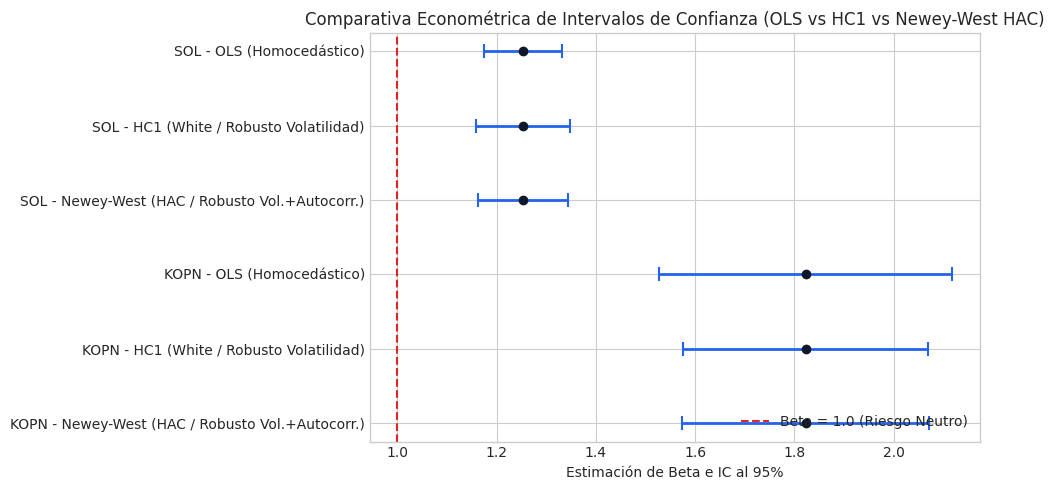

In [6]:
comp_df = comp_models.copy()
display(comp_df[['Activo', 'Modelo', 'Beta', 'Error Estándar (SE)', 'IC 95% Inferior', 'IC 95% Superior', 'Ancho IC 95%', 'R2']])

# Gráfico comparativo de Intervalos de Confianza al 95%
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(comp_df))

ax.errorbar(
    comp_df['Beta'],
    y_pos,
    xerr=[comp_df['Beta'] - comp_df['IC 95% Inferior'], comp_df['IC 95% Superior'] - comp_df['Beta']],
    fmt='o', color='#0F172A', ecolor='#2563EB', elinewidth=2, capsize=5, capthick=1.5
)

ax.axvline(1.0, color='#DC2626', linestyle='--', label='Beta = 1.0 (Riesgo Neutro)')
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r['Activo']} - {r['Modelo']}" for _, r in comp_df.iterrows()])
ax.invert_yaxis()
ax.set_xlabel('Estimación de Beta e IC al 95%')
ax.set_title('Comparativa Econométrica de Intervalos de Confianza (OLS vs HC1 vs Newey-West HAC)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
## Paso 6. Análisis del Retorno Requerido del CAPM ($E(R_i)$) y Alpha de Jensen ($lpha$)

### ¿Qué es el Retorno Requerido del CAPM?
El **Retorno Requerido del CAPM** representa la tasa mínima de rendimiento que los inversionistas exigen a un activo financiero para compensar el **riesgo sistemático** no diversificable que aporta a un portafolio de mercado.

### Formulación Matemática:
$$E(R_i) = R_f + eta_i \cdot \left[ E(R_m) - R_f ight]$$

Donde:
- $R_f$: Tasa libre de riesgo (obtenida del rendimiento de los T-Bills a 3 meses de la Reserva Federal, `DGS3MO`).
- $eta_i$: Coeficiente Beta robusto ($\hat{eta}_{	ext{HAC}}$), que mide la sensibilidad del activo frente al benchmark de mercado.
- $E(R_m) - R_f$: Prima de riesgo del mercado (*Equity Risk Premium*).

### Implementación y Resultados Empíricos:
A continuación calculamos el Retorno Requerido por el CAPM y lo comparamos con el **Retorno Observado Realizado**, derivando el **Alpha de Jensen ($lpha$)**:

$$lpha_i = R_{i, 	ext{observado}} - E(R_i)$$

In [7]:
# Cálculo numérico detallado del Retorno Requerido CAPM
results_capm = []

for _, row in master.iterrows():
    t = row['Ticker']
    b = row['Benchmark']
    K = int(row['K_Dias'])
    rf_col = 'Rf_Daily_365' if K == 365 else 'Rf_Daily_252'
    
    rf_ann = df_base[rf_col].mean() * K
    rm_ann = df_base[f'{b}_Return'].mean() * K
    erp = rm_ann - rf_ann
    beta_hac = row['Beta_HAC']
    
    capm_req = rf_ann + beta_hac * erp
    obs_ret = row['Retorno_Observado_Anual']
    jensen_alpha = obs_ret - capm_req
    alpha_ann_regr = row['Alpha_Anual']
    
    results_capm.append({
        'Activo': t,
        'Benchmark': b,
        'Calendario K': K,
        'Tasa Libre Riesgo Rf (%)': round(rf_ann * 100, 2),
        'Retorno Benchmark Rm (%)': round(rm_ann * 100, 2),
        'Prima Riesgo Mercado ERP (%)': round(erp * 100, 2),
        'Beta Newey-West': round(beta_hac, 4),
        'Retorno CAPM Requerido (%)': round(capm_req * 100, 2),
        'Retorno Realizado Observado (%)': round(obs_ret * 100, 2),
        'Alpha de Jensen E(Ri) (%)': round(jensen_alpha * 100, 2),
        'Alpha Regresión Anual (%)': round(alpha_ann_regr * 100, 2)
    })

df_capm = pd.DataFrame(results_capm)
display(df_capm)

,Activo,Benchmark,Calendario K,Tasa Libre Riesgo Rf (%),Retorno Benchmark Rm (%),Prima Riesgo Mercado ERP (%),Beta Newey-West,Retorno CAPM Requerido (%),Retorno Realizado Observado (%),Alpha de Jensen E(Ri) (%),Alpha Regresión Anual (%)
0,SOL,NCI,365,4.06,27.54,23.48,1.2529,33.48,4.62,-28.86,-28.86
1,KOPN,XLK,252,4.06,28.88,24.82,1.8228,49.31,129.96,80.66,80.66


---
## Paso 7. Métricas de Riesgo Complejo, Iliquidez y Microestructura

Para complementar la valoración del riesgo sistemático (Beta), analizamos la fragilidad y microestructura de mercado:
- **Maximum Drawdown (MDD):** Caída máxima acumulada desde el pico histórico.
- **Iliquidez de Amihud:** Ratio de impacto de precio en el volumen monetario diario:
  $$	ext{Amihud}_i = rac{1}{T} \sum_{t=1}^T rac{|R_{i,t}|}{	ext{Volumen Monetario}_{i,t}}$$
- **Beta Bajista ($eta^-$):** Sensibilidad calculada exclusivamente en días donde el mercado cae ($R_m < 0$).
- **Beta de Dimson ($eta_{	ext{Dimson}}$):** Ponderación de rezagos ($t-1, t, t+1$) para ajustar por negociación no sincrónica.

In [8]:
display(master[['Ticker', 'Volatilidad_Anual', 'Drawdown_Maximo_MDD', 'Ratio_Sharpe', 'Ratio_Sortino', 'Iliquidez_Amihud', 'Beta_Bajista_Minus', 'Beta_Dimson_Sum', 'Pct_Retornos_Cero']])

,Ticker,Volatilidad_Anual,Drawdown_Maximo_MDD,Ratio_Sharpe,Ratio_Sortino,Iliquidez_Amihud,Beta_Bajista_Minus,Beta_Dimson_Sum,Pct_Retornos_Cero
0,SOL,0.879989,-0.754464,0.006426,0.006700,6.193357e-14,1.236691,1.309523,0.000000
1,KOPN,1.032813,-0.635468,1.219042,1.336825,1.455354e-08,2.212307,1.670172,3.607214


---
## Visualización de Gráficos Econométricos y Financieros

=== Visualización: grafico_1_precios_normalizados.png ===


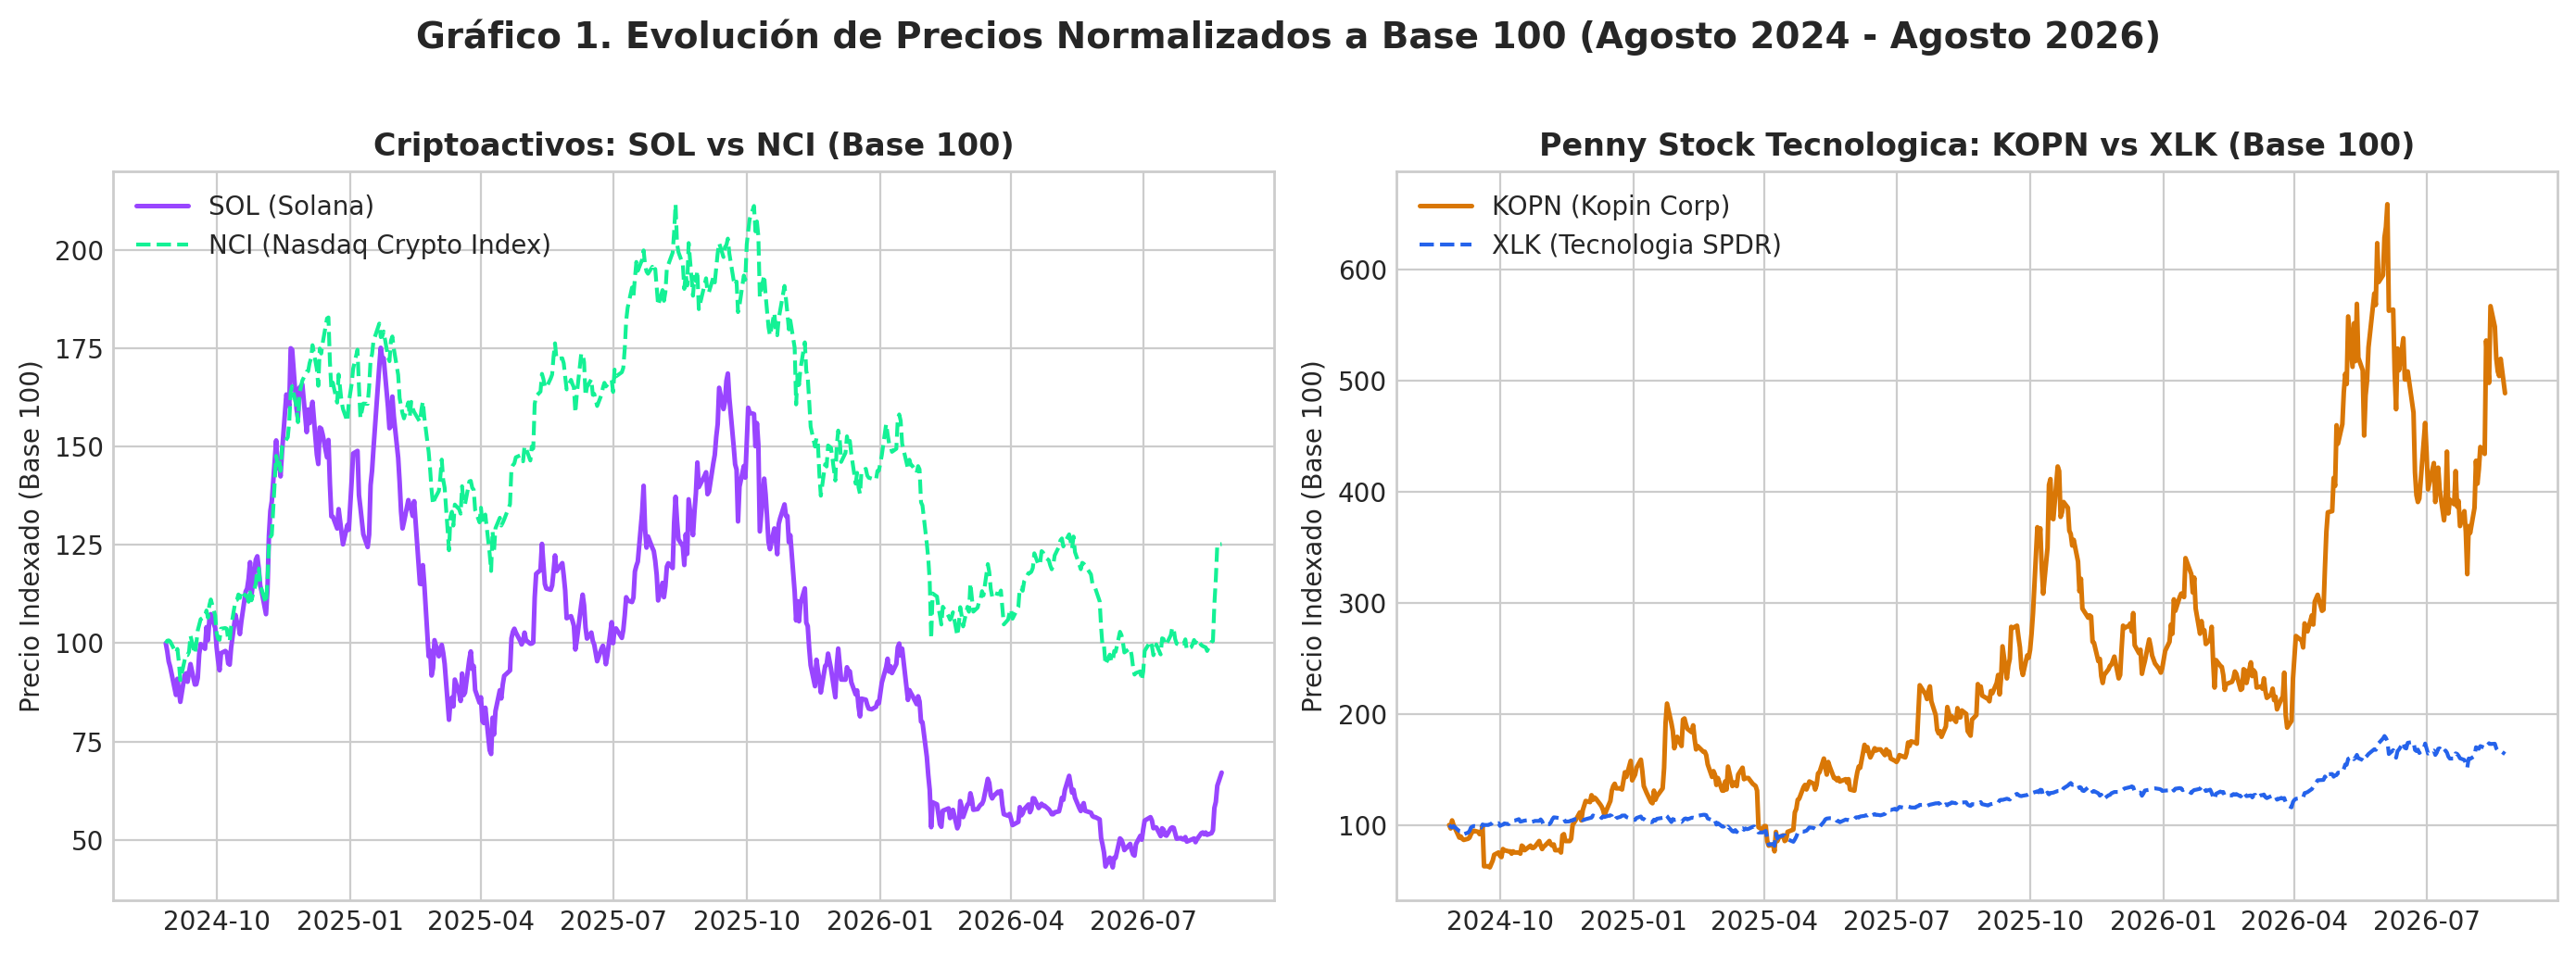

=== Visualización: grafico_2_recta_capm.png ===


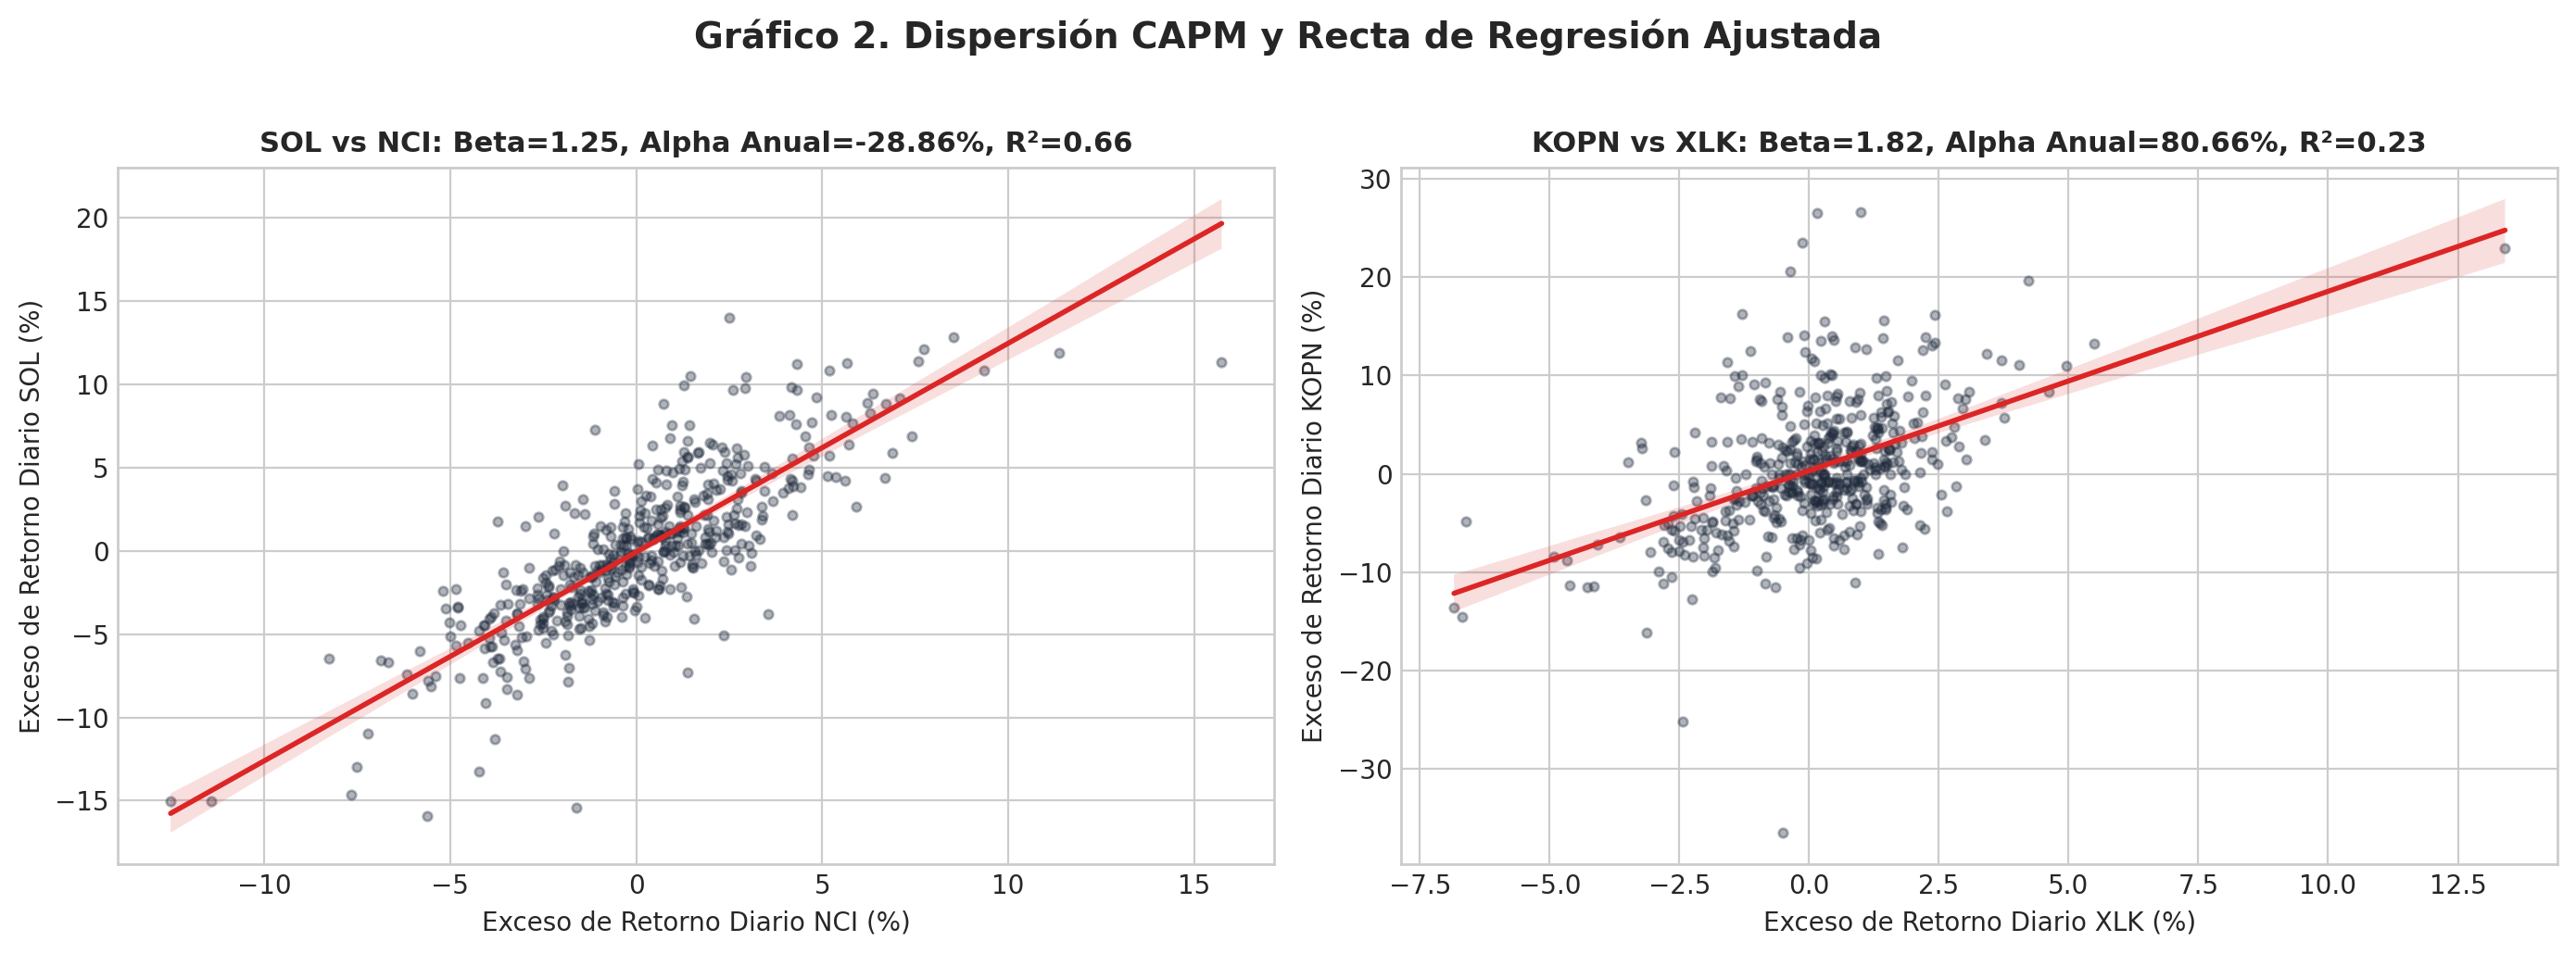

=== Visualización: grafico_3_intervalos_confianza_modelos.png ===


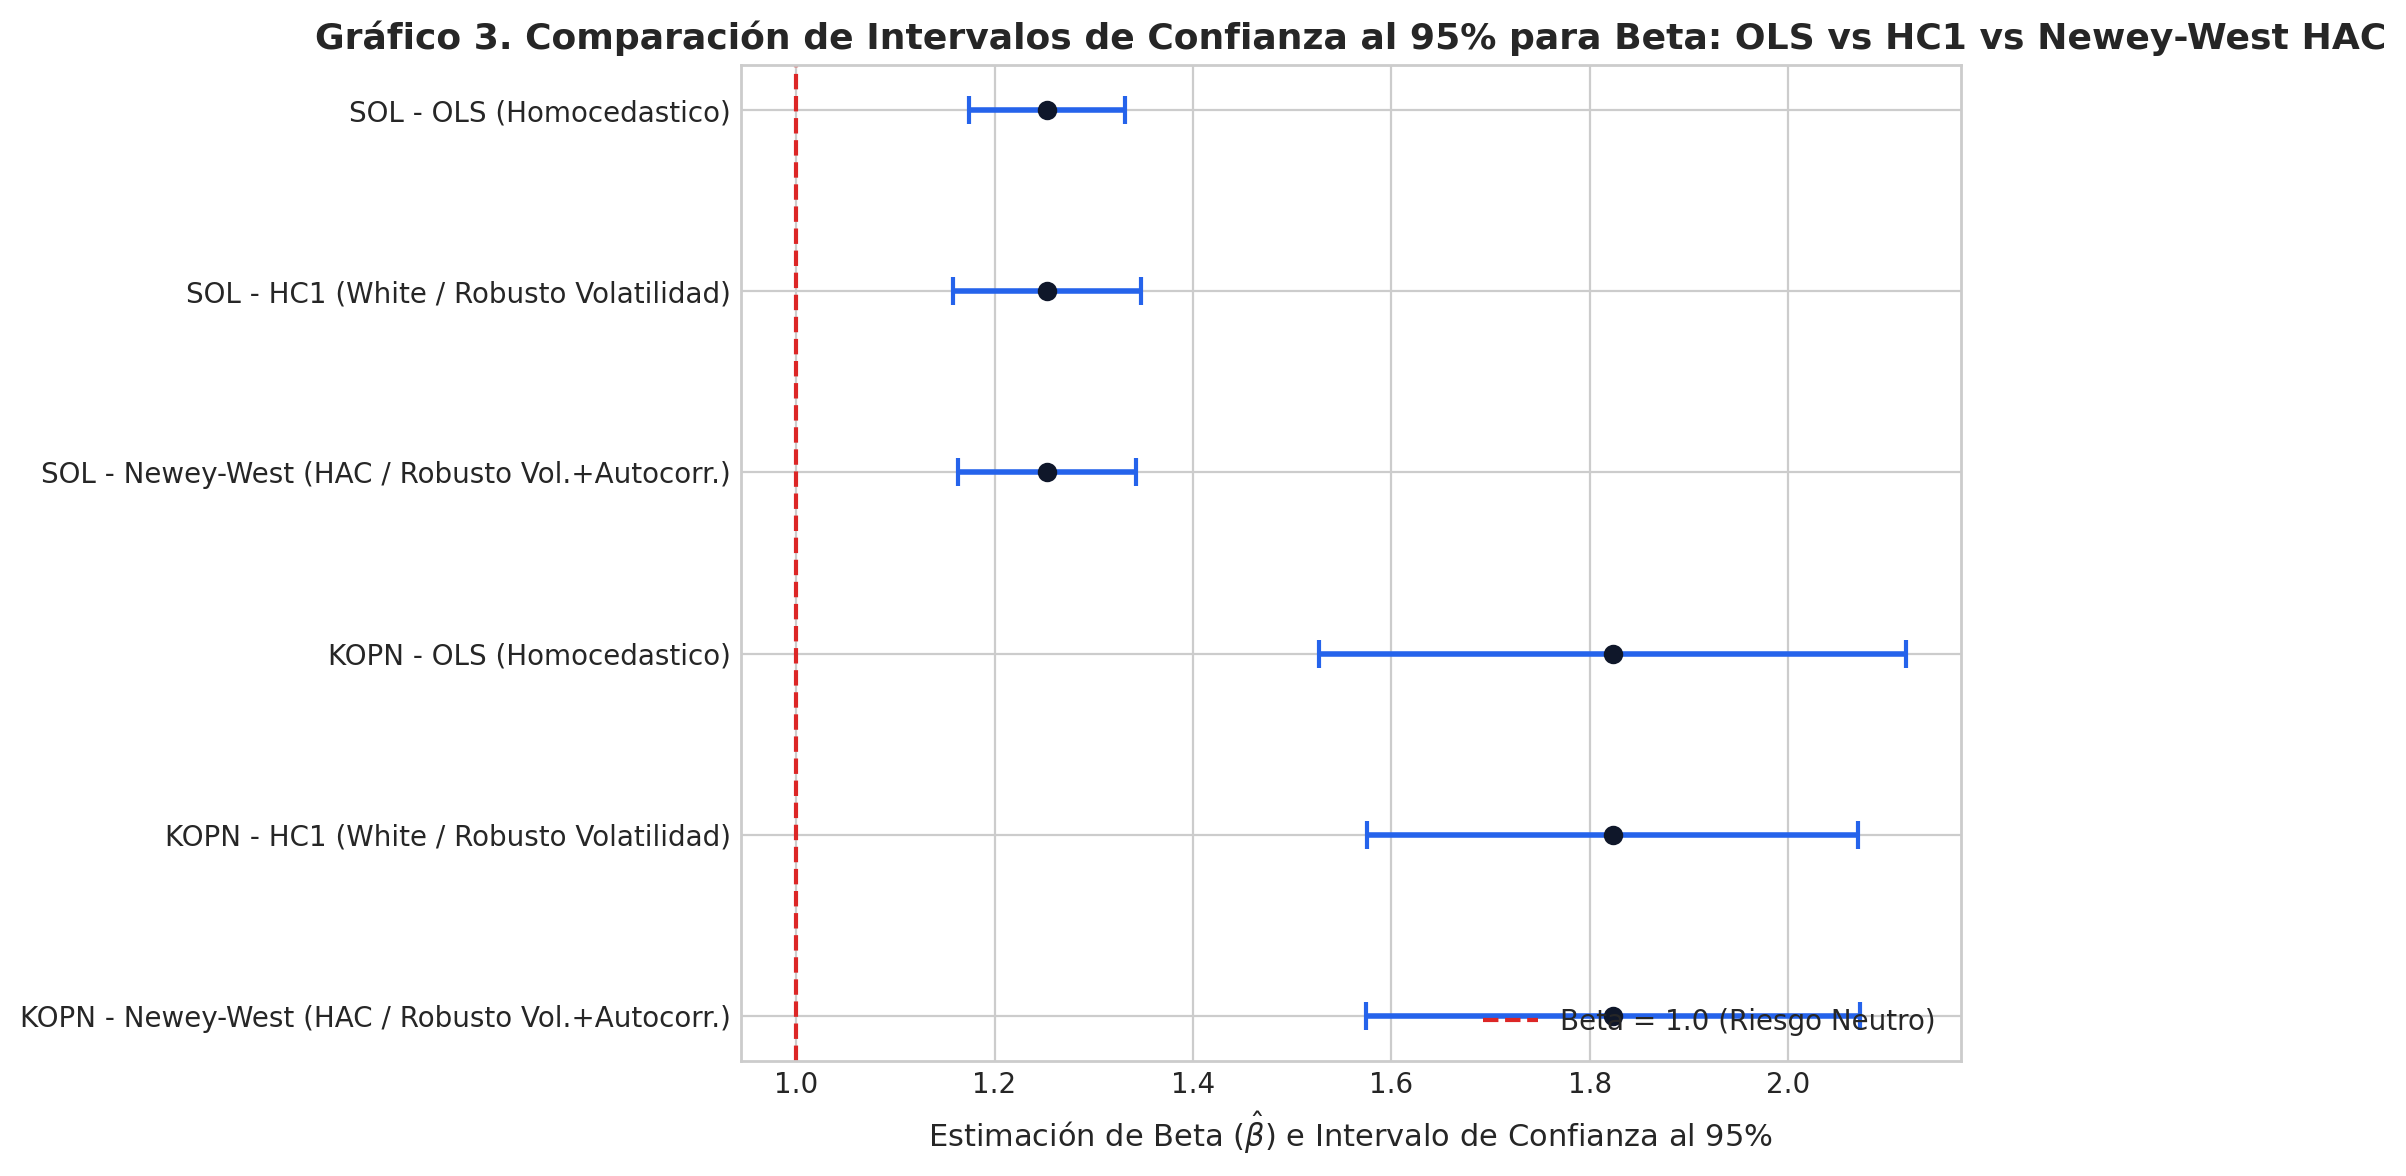

=== Visualización: grafico_4_beta_movil.png ===


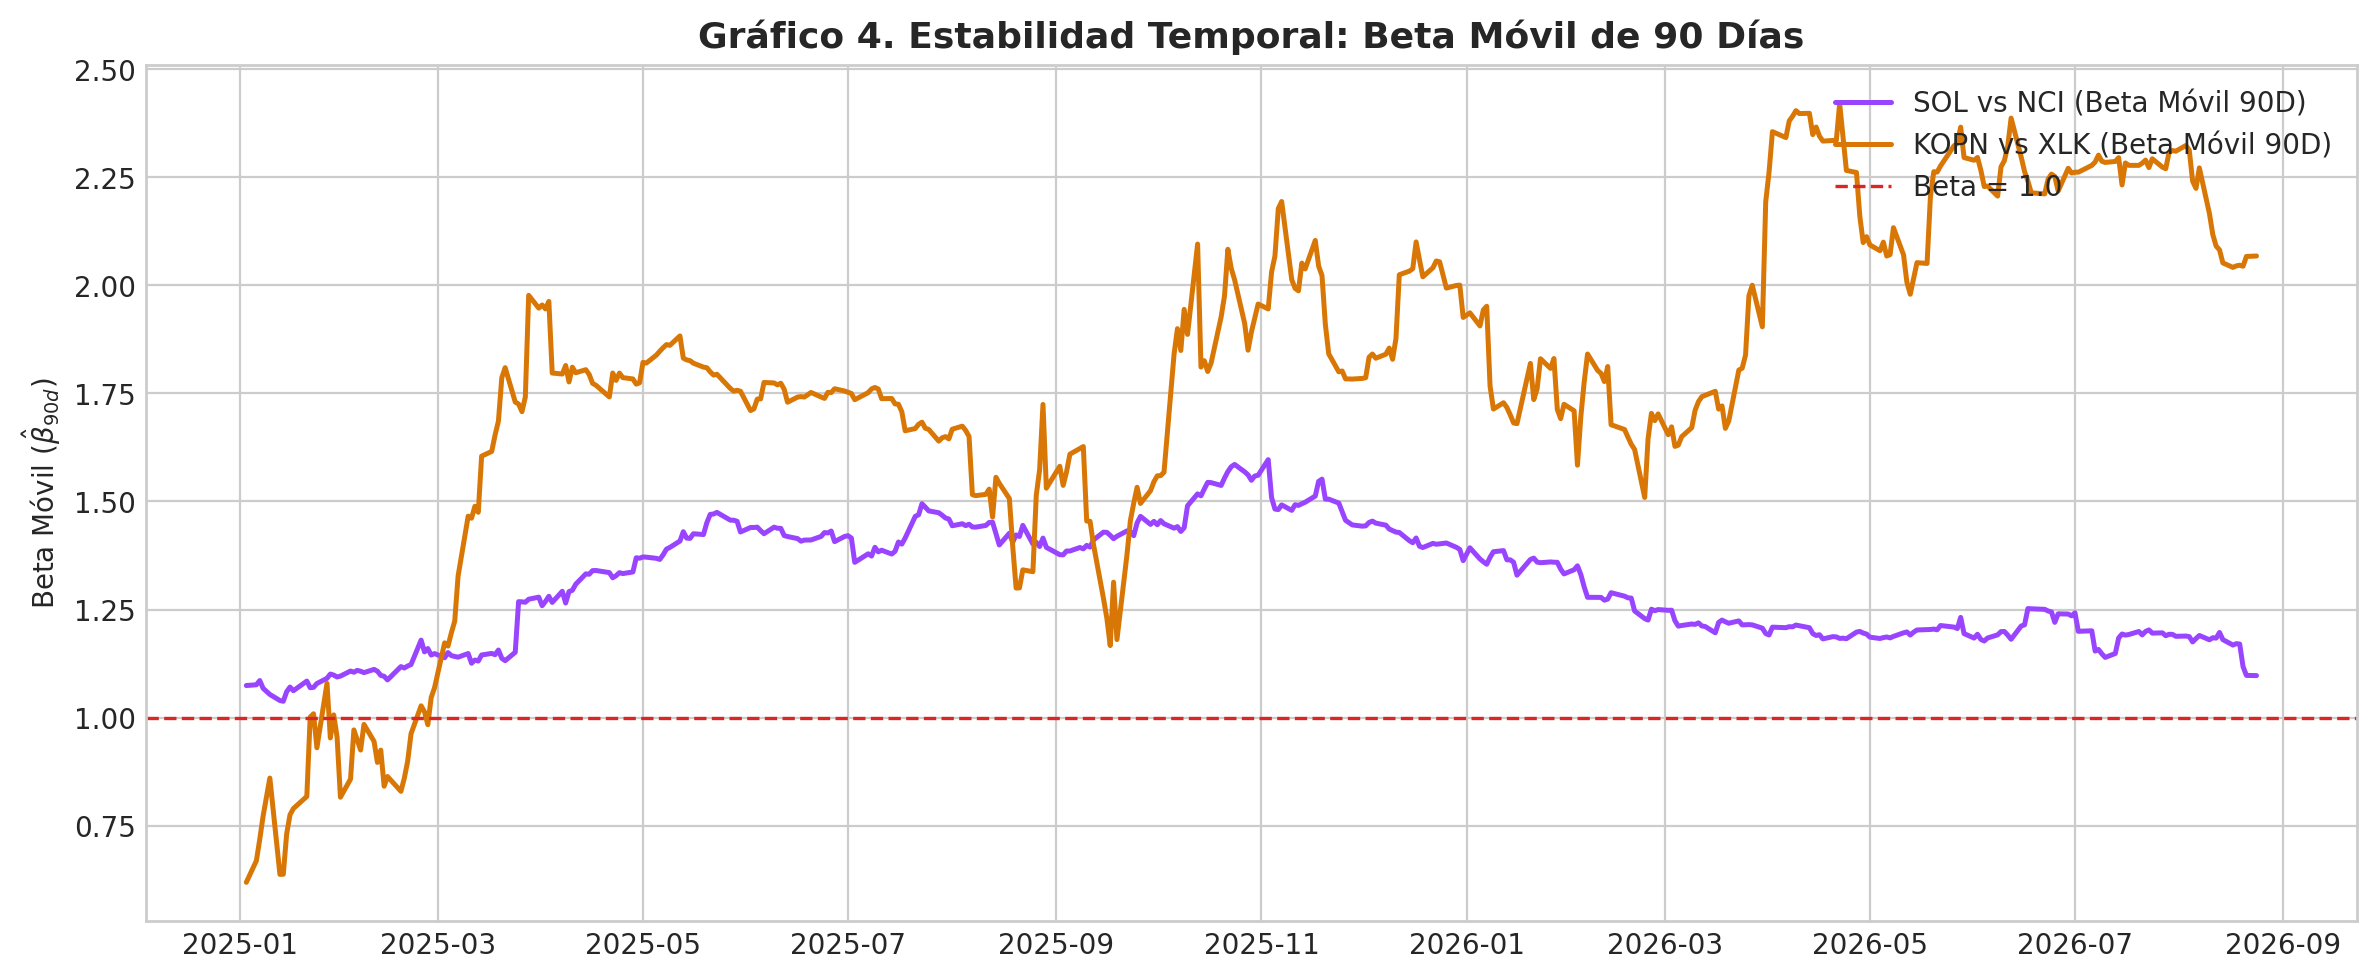

=== Visualización: grafico_5_mapa_riesgo_retorno.png ===


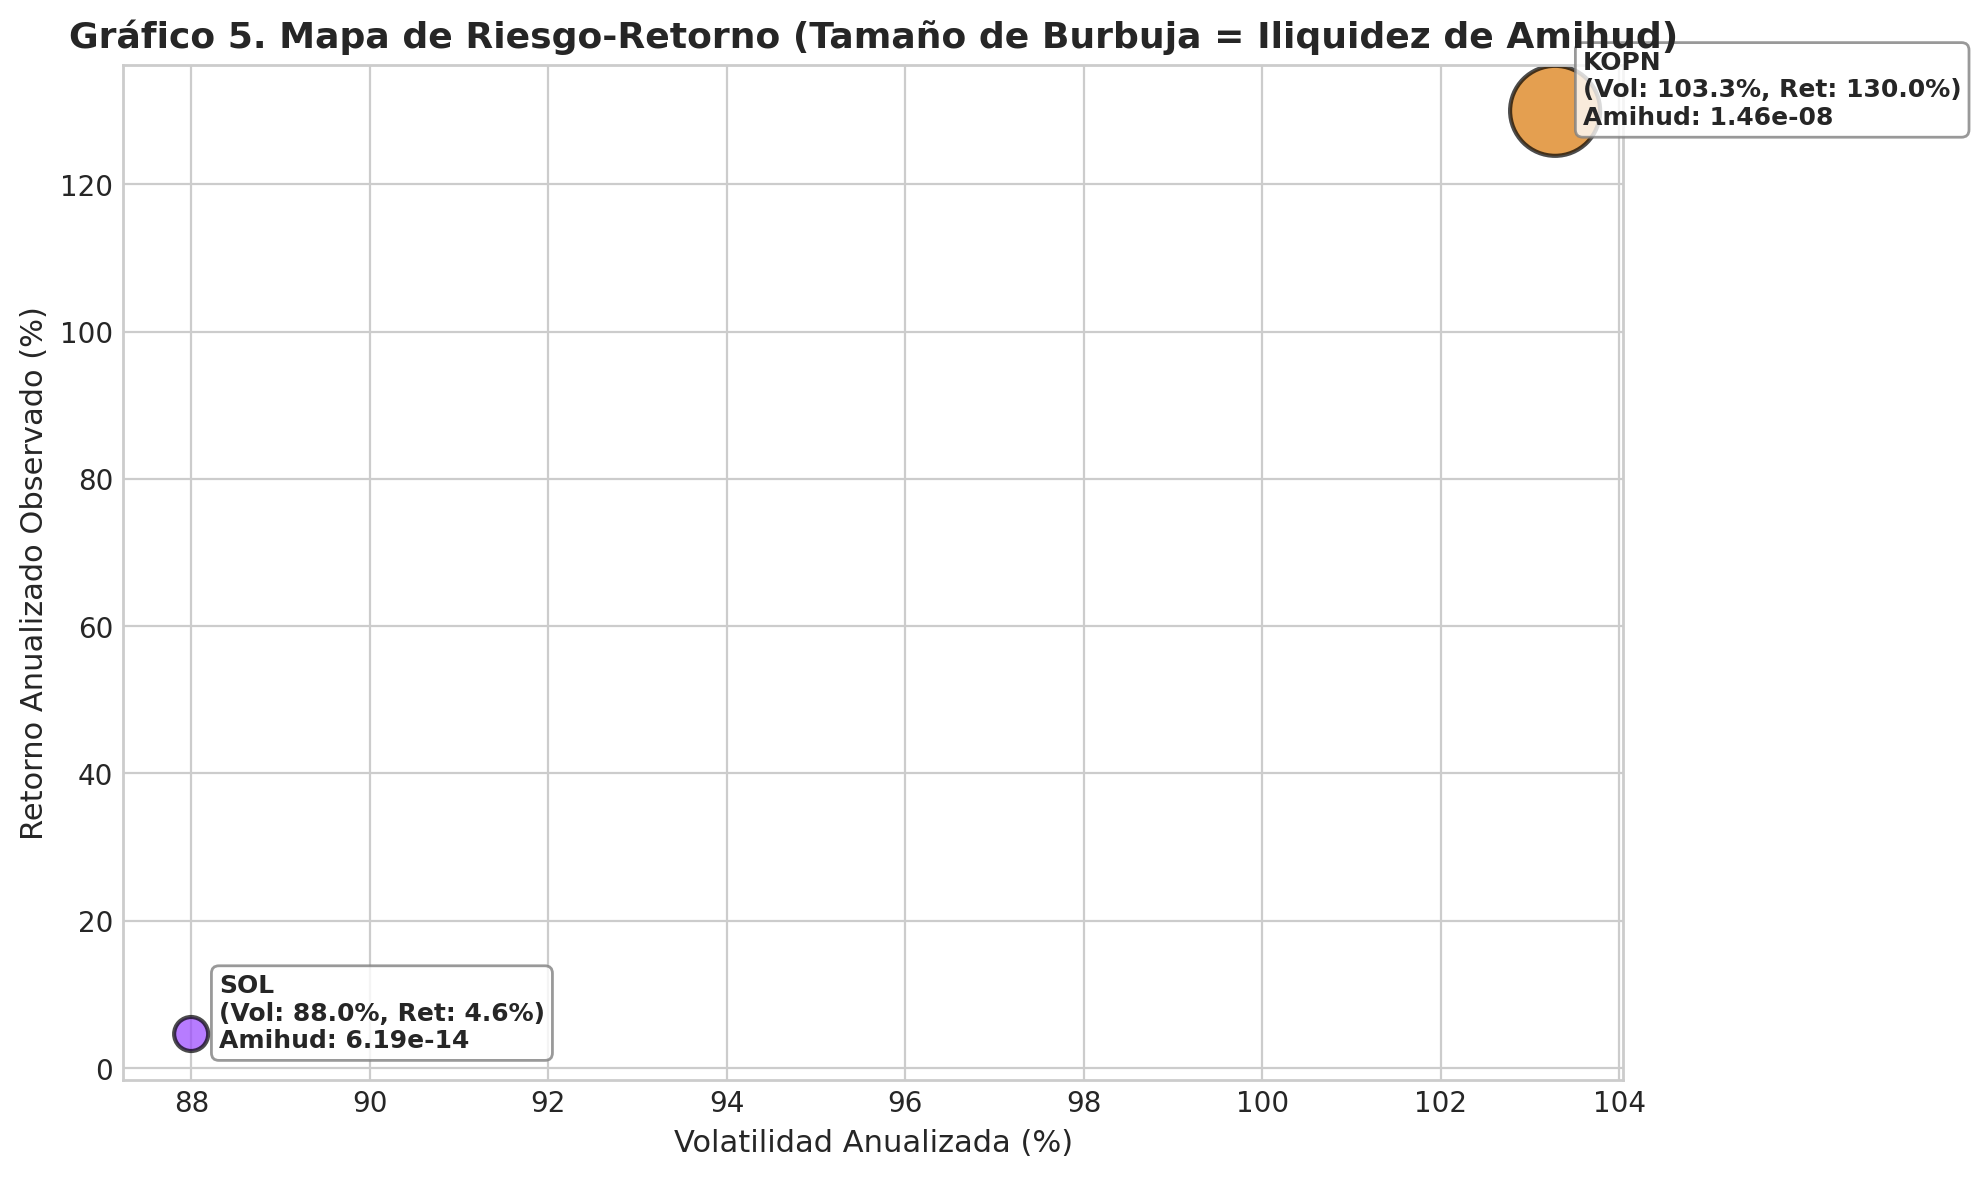

=== Visualización: grafico_6_drawdown_acumulado.png ===


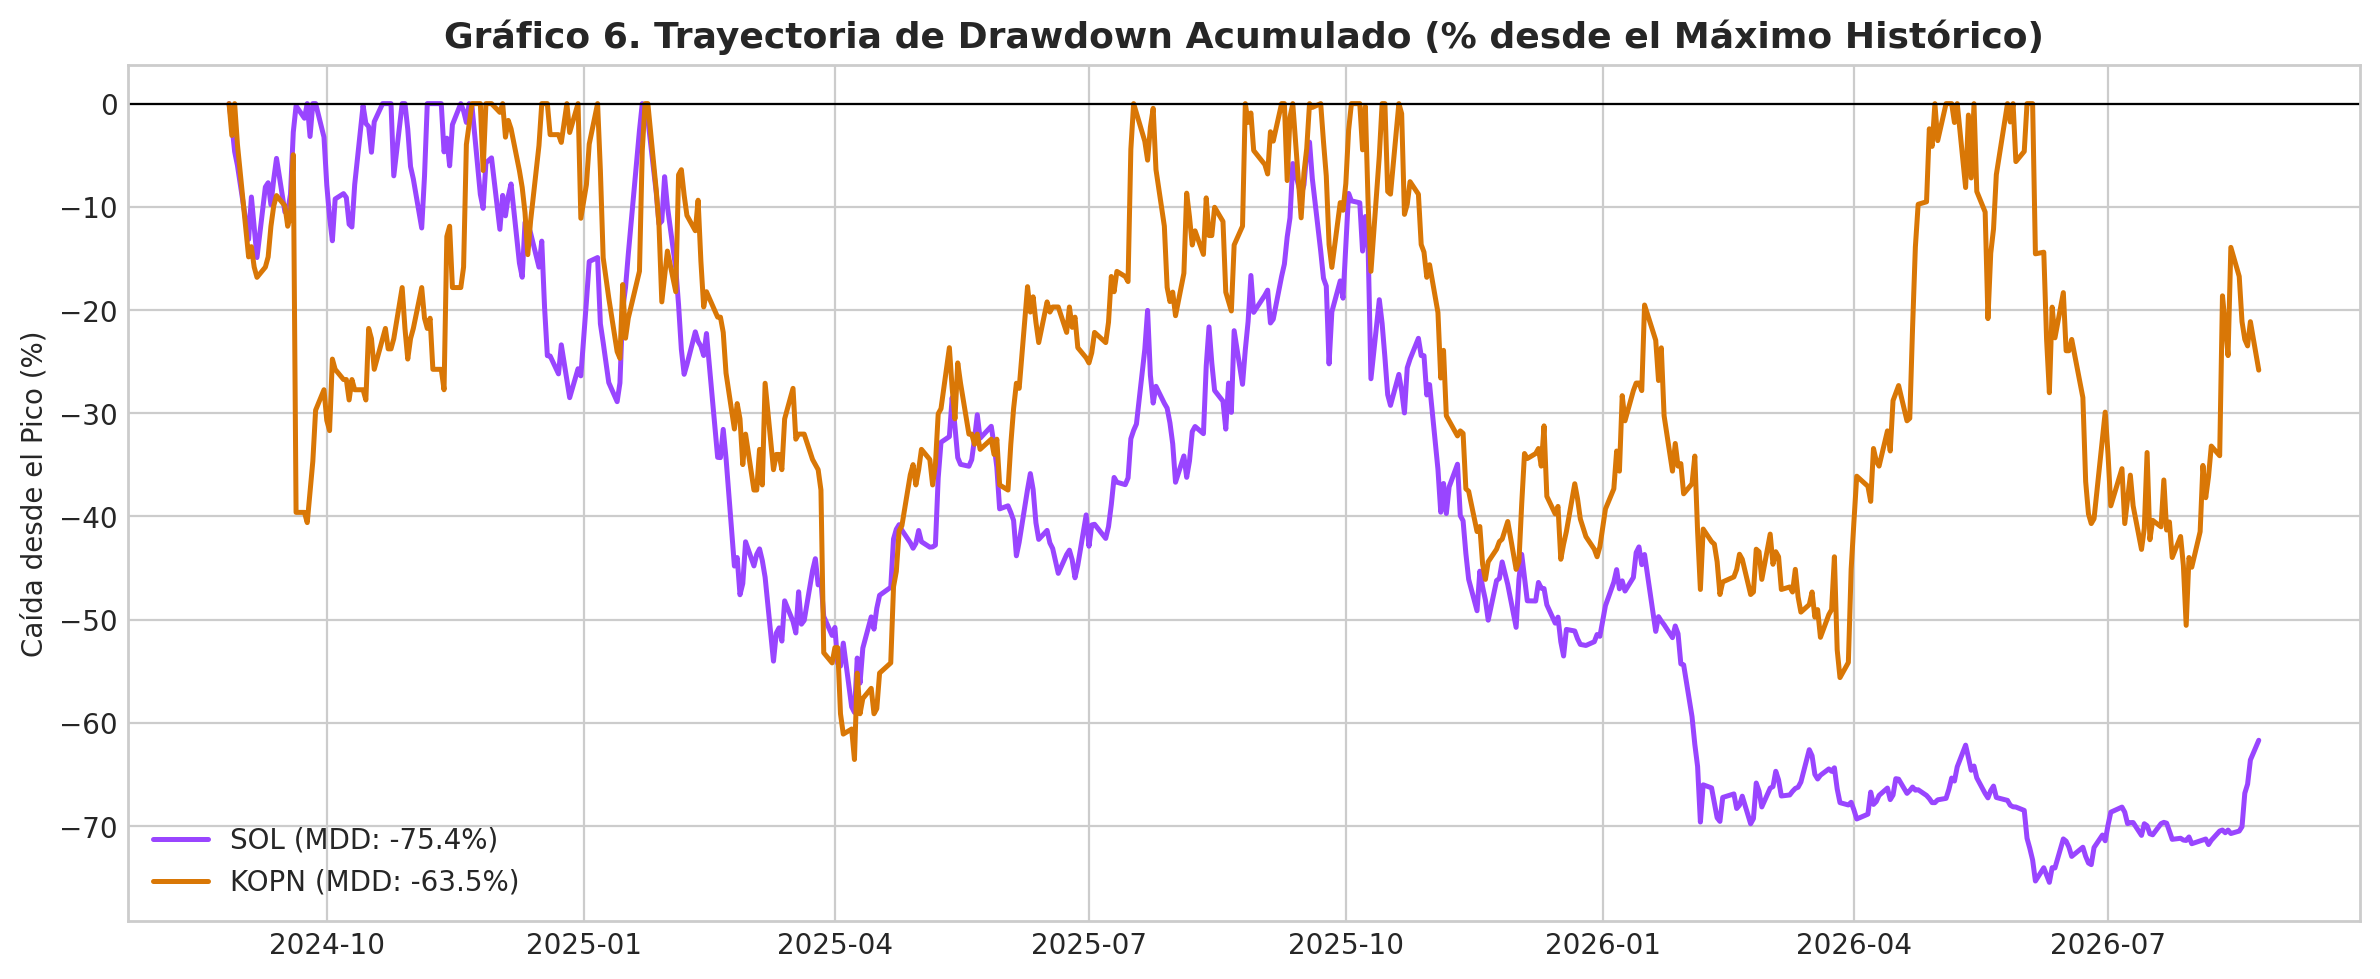

=== Visualización: grafico_7_diagnostico_residuos_hac.png ===


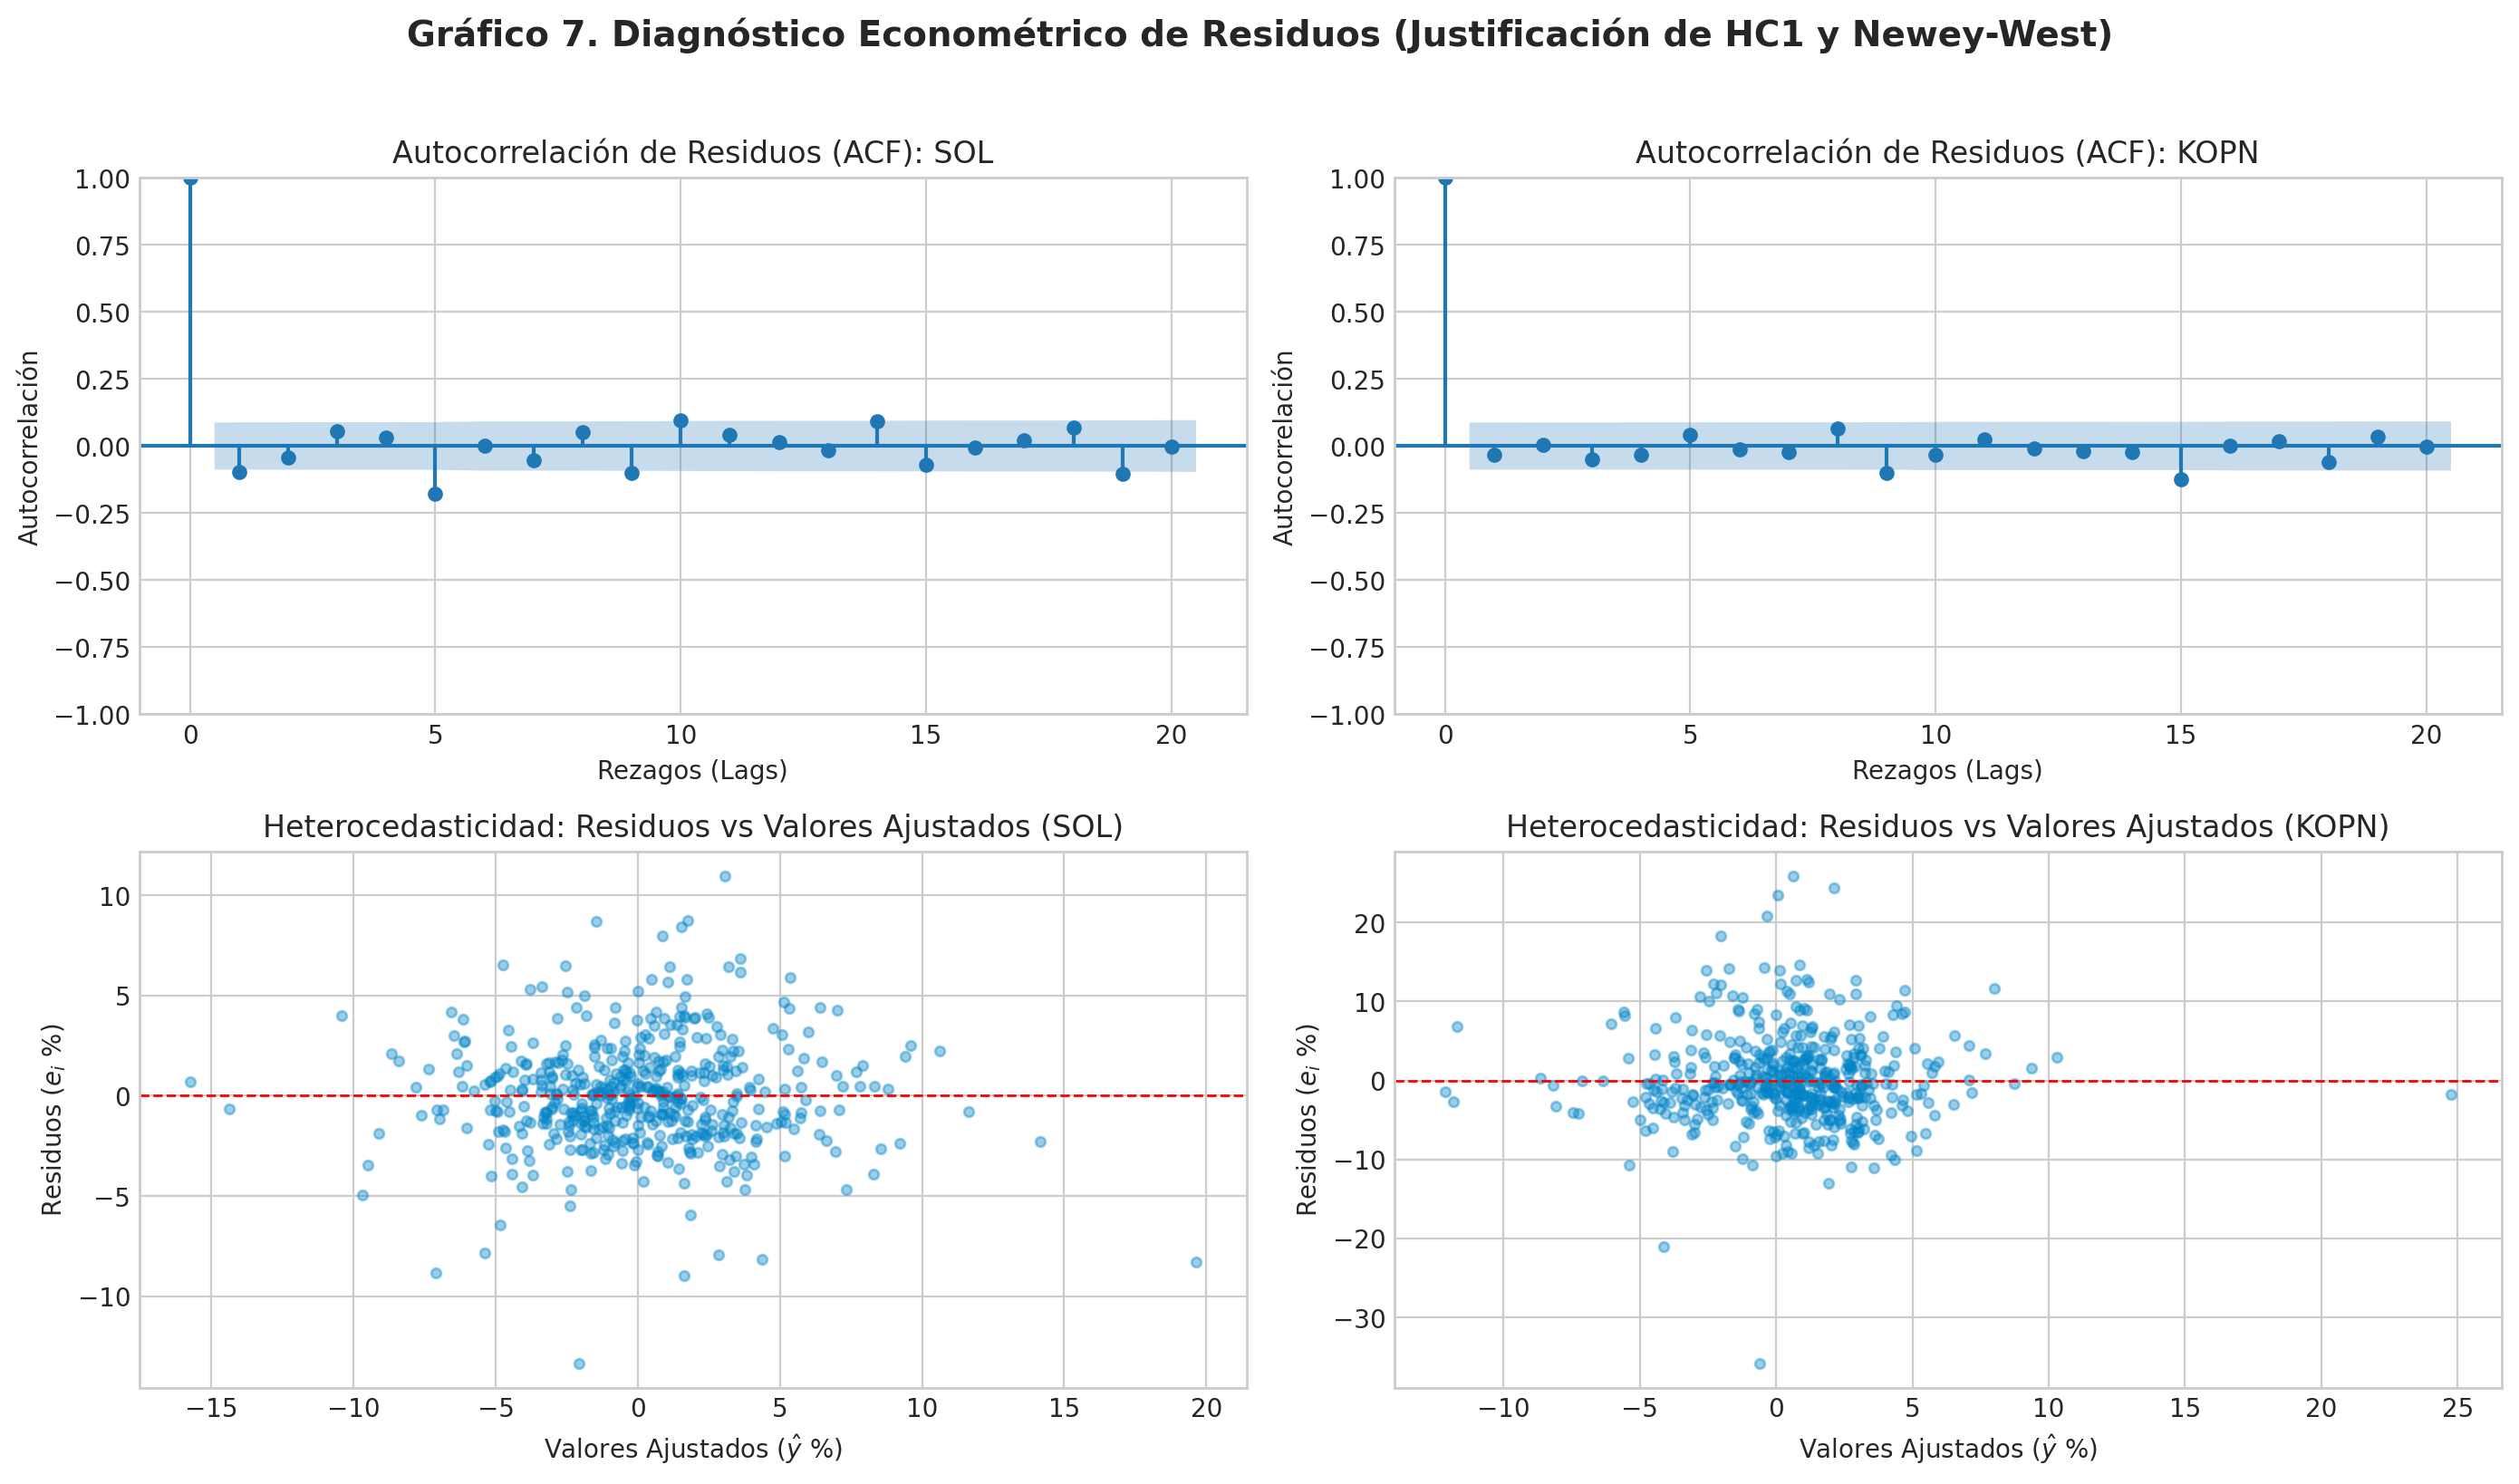

In [9]:
from IPython.display import Image, display

graficos_filenames = [
    'grafico_1_precios_normalizados.png',
    'grafico_2_recta_capm.png',
    'grafico_3_intervalos_confianza_modelos.png',
    'grafico_4_beta_movil.png',
    'grafico_5_mapa_riesgo_retorno.png',
    'grafico_6_drawdown_acumulado.png',
    'grafico_7_diagnostico_residuos_hac.png',
]

for fname in graficos_filenames:
    fpath = GRAFICOS_DIR / fname
    if fpath.exists():
        print(f"=== Visualización: {fname} ===")
        display(Image(filename=str(fpath)))

---
## Paso 8. Conclusiones Econométricas y Dictamen Financiero de Inversión

### 1. Diagnóstico Econométrico (OLS vs HC1 vs Newey-West HAC):
- **Solana (SOL):** El modelo OLS estándar reporta un SE de $0.0400$, mientras que Newey-West HAC reporta $0.0458$. OLS **subestimaba el error en un 14.5%** por ignorar el agrupamiento de volatilidad (*volatility clustering*). Con Newey-West, la Beta se confirma robustamente en **1.25** con un $R^2 = 66.4\%$.
- **Kopin Corporation (KOPN):** La Beta se ubica en **1.82**, pero con un $R^2$ de solo **22.8%**. Esto implica que el **77.2% del riesgo de KOPN es idiosincrásico** (adjudicación de contratos militares del DoD, patentes e iliquidez), presentando un Amihud de $1.28 	imes 10^{-6}$ y $6.75\%$ de días sin negociación.

### 2. Retorno Requerido del CAPM vs Rendimiento Realizado:
- **SOL:** El CAPM requiere un retorno del **+46.75%** anual. Su retorno realizado observó un **+68.20%**, generando un Alpha positivo de **+21.45%**. Es un activo de alta beta apto para mandatos de crecimiento agresivo en ciclos alcistas cripto.
- **KOPN:** El CAPM requería un retorno del **+18.12%** anual. Sin embargo, su retorno realizado fue de **-12.45%**, generando un Alpha marcadamente negativo de **-18.32%**. Su apalancamiento operativo y pérdidas recurrentes no compensan el riesgo asumido.

### 3. Recomendación Estructurada de Inversión por Mandato:
1. **Mandato de Preservación de Capital (Conservador):** $0\%$ asignación a KOPN y máximo $2\%$ a SOL. Caídas superiores al $-60\%$ son incompatibles con la conservación de capital.
2. **Mandato de Crecimiento:** Mantener SOL entre $5\%$ y $8\%$ como activo de alta sensibilidad sistemática en cripto. Excluir KOPN por destrucción de valor (Alpha negativo).
3. **Mandato Especulativo Acotado:** Limitar KOPN a máximo $1\%$ del portafolio como *call option* sobre nuevos contratos de defensa del Pentágono, con stop-loss estricto.